# A 수집 기록 (TOPIS 통행속도, 교통예보, 실시간 속도)

A(강민주)가 받은 자료를 어떤 코드로, 어떻게 돌렸고, 무엇이 나왔는지 한 곳에서 보는 노트북이다.
수집 본체는 `crawling/*.py`(터미널, GitHub Actions에서 실행)에 있고, 이 노트북은 핵심 코드, 실행 로그, 화면 캡처, 결과 표를 읽어서 보여 주기만 한다.
실행해도 아무것도 다시 받거나 덮어쓰지 않는다.

| # | 자료 | 방법 | 코드 | 실행 |
| --- | --- | --- | --- | --- |
| 1 | TOPIS 월별 차량통행속도 (50개월) | Selenium + 네트워크 분석으로 찾은 다운로드 요청 | `crawling/topis_speed.py` | 내 컴퓨터, 11/20 ~ 11/25 |
| 2 | TOPIS 교통예보 스냅샷 | Selenium + 페이지가 쓰는 JSON 요청 직접 호출 | `crawling/topis_forecast.py` | GitHub Actions 매일 05:17 (12/11까지) |
| 3 | 실시간 도로 소통 정보 | 서울 열린데이터광장 TrafficInfo API | `crawling/realtime_speed.py` | GitHub Actions 평일 출퇴근 (12/11까지) |

자동 수집(2, 3) 결과는 main이 아니라 `data-collect` 브랜치에 쌓인다. 이 노트북은 `git fetch origin data-collect` 뒤의 내용을 읽는다.

In [1]:
from pathlib import Path
import ast, json, re, subprocess
import pandas as pd
from IPython.display import Image, Markdown, display


def find_project_root(start=None):
    """지금 폴더에서 위로 올라가며 README.md와 .git이 있는 저장소 루트를 찾는다."""
    current = Path(start or Path.cwd()).resolve()
    for candidate in (current, *current.parents):
        if (candidate / 'README.md').is_file() and (candidate / '.git').exists():
            return candidate
    raise FileNotFoundError('프로젝트 루트를 찾지 못했습니다.')


ROOT = find_project_root()
pd.set_option('display.max_columns', 30)


def show_func(rel, *names):
    """파이썬 파일에서 함수 몇 개만 골라 보여 준다 (import 하지 않아서 Selenium 없이도 된다)."""
    src = (ROOT / rel).read_text(encoding='utf-8')
    lines = src.splitlines()
    for node in ast.parse(src).body:
        if isinstance(node, (ast.FunctionDef, ast.ClassDef)) and node.name in names:
            start = (node.decorator_list[0].lineno if node.decorator_list else node.lineno) - 1
            body = '\n'.join(lines[start:node.end_lineno])
            display(Markdown(f'**`{rel}`, `{node.name}()`** ({start + 1}–{node.end_lineno}행)\n```python\n{body}\n```'))


def log_lines(rel, pattern=None, n=8):
    """A 로그(시각 | 내용): 기간, 줄 수 + (pattern에 맞는) 마지막 n줄."""
    lines = [l for l in (ROOT / rel).read_text(encoding='utf-8', errors='replace').splitlines() if l.strip()]
    print(f'{rel}, {len(lines):,}줄, {lines[0][:16]} ~ {lines[-1][:16]}')
    pick = [l for l in lines if re.search(pattern, l)] if pattern else lines
    print('\n'.join('  ' + l[:170] for l in pick[-n:]))
    return lines


def collected(prefix):
    """data-collect 브랜치에서 prefix 아래 파일 목록."""
    out = subprocess.run(['git', 'ls-tree', '-r', '--name-only', 'origin/data-collect', prefix],
                         cwd=ROOT, capture_output=True, text=True, encoding='utf-8')
    if out.returncode:
        print('data-collect 브랜치를 못 읽음: git fetch origin data-collect 를 먼저 실행')
        return []
    return out.stdout.split()


def collected_text(rel):
    return subprocess.run(['git', 'show', f'origin/data-collect:{rel}'], cwd=ROOT, capture_output=True,
                          text=True, encoding='utf-8').stdout

---
## 1. TOPIS 월별 차량통행속도, Selenium (A의 동적 크롤링)

- 출처: TOPIS 자료실, 서울시 차량통행속도 (연도를 고르면 목록이 비동기로 다시 그려지는 페이지)
- 흐름: 일별 탭 열기 -> 연도 선택 -> 목록이 새 연도로 바뀔 때까지 대기, 검증 -> 네트워크 기록에서 다운로드 요청 확인 -> Selenium 쿠키로 `requests` 세션 -> 월별 엑셀 받기 -> 검증 후 CSV 변환
- 실행: `python crawling/topis_speed.py --all` (이미 받은 달은 건너뛰고, 실패한 달만 다시 받음, `--recheck`로 검증만 다시)
- 대상: 겨울 10~3월, 여름 4~9월 x 4시즌 + 2022-07, 08 (평소값 앞 4주, 범위 밖 예측용). 결과는 팀 공유 드라이브. 2022-07은 나중에 따로 받아 manifest에는 없다 (49개월)

### 1-1. 핵심 코드

In [2]:
show_func('crawling/topis_speed.py', 'select_year_and_read', 'make_session', 'download', 'verify_and_convert')

**`crawling/topis_speed.py`, `select_year_and_read()`** (131–163행)
```python
def select_year_and_read(driver, wait, year):
    """연도를 고르고 목록이 그 연도로 바뀐 걸 확인한 뒤 {월: 다운로드 정보}를 돌려준다."""
    box = driver.find_element(By.ID, "srchYear")
    if not box.find_elements(By.CSS_SELECTOR, f"option[value='{year}']"):
        raise RuntimeError(f"연도 목록에 {year}년이 없음")
    Select(box).select_by_value(str(year))

    def list_is_new(d):
        # 제목과 12칸, 그리고 모든 파일명이 선택한 연도여야 '새 목록'으로 인정
        if d.find_element(By.ID, "selectedYear").text.strip() != f"{year}년":
            return False
        cells = d.find_elements(By.CSS_SELECTOR, "#resultData1_2 > div")
        if len(cells) != 12:
            return False
        names = [m.group(1) for c in cells
                 for m in [ONCLICK_RE.search(c.get_attribute("innerHTML"))] if m]
        return all(f"{year}년" in n for n in names)

    wait.until(list_is_new)

    files = {}
    for h5 in driver.find_elements(By.CSS_SELECTOR, "#resultData1_2 h5[onclick]"):
        m = ONCLICK_RE.search(h5.get_attribute("onclick"))
        if not m:
            continue
        name, path_nm, seq, div = m.groups()
        nm = NAME_RE.search(name)
        if not nm or int(nm.group(1)) != year:
            log(f"  [건너뜀] 연도가 맞지 않는 항목: {name}")
            continue
        files[int(nm.group(2))] = {"apndFileNm": name, "apndFilePathNm": path_nm,
                                   "bdwrSeq": seq, "blbdDivCd": div}
    return files
```

**`crawling/topis_speed.py`, `make_session()`** (181–190행)
```python
def make_session(driver):
    """Selenium 브라우저의 쿠키를 그대로 쓰는 requests 세션"""
    s = requests.Session()
    for c in driver.get_cookies():
        s.cookies.set(c["name"], c["value"], domain=c.get("domain"))
    s.headers.update({
        "User-Agent": driver.execute_script("return navigator.userAgent"),
        "Referer": PAGE_URL,
    })
    return s
```

**`crawling/topis_speed.py`, `download()`** (201–222행)
```python
def download(session, info, dest):
    tmp = dest.with_suffix(".part")
    for attempt in range(1, RETRIES + 1):
        try:
            with session.post(DOWNLOAD_URL, data=info, stream=True, timeout=(10, 120)) as r:
                r.raise_for_status()
                expected = int(r.headers.get("Content-Length", 0))
                with tmp.open("wb") as f:
                    for chunk in r.iter_content(1024 * 1024):
                        f.write(chunk)
            got = tmp.stat().st_size
            if expected and got != expected:
                raise IOError(f"크기 불일치 {got} / {expected} bytes")
            if not looks_like_xlsx(tmp):
                raise IOError("엑셀 형식이 아님")
            tmp.replace(dest)
            return
        except (requests.RequestException, IOError) as e:
            log(f"  [재시도 {attempt}/{RETRIES}] {dest.name}: {e}")
            tmp.unlink(missing_ok=True)
            time.sleep(5 * attempt)
    raise RuntimeError(f"{RETRIES}번 시도 후 실패: {dest.name}")
```

**`crawling/topis_speed.py`, `verify_and_convert()`** (226–275행)
```python
def verify_and_convert(xlsx, csv_path, y, m):
    """엑셀을 한 번 읽으면서 CSV로 쓰고 품질 지표를 센다."""
    wb = load_workbook(xlsx, read_only=True)
    rows = wb.active.iter_rows(values_only=True)
    header = list(next(rows))
    notes = []
    if header[:12] != EXPECTED_HEAD or len(header) != N_COLS:
        notes.append(f"열 구성 다름({len(header)}열)")

    prefix = f"{y}{m:02d}"
    dates, links = set(), set()
    n_rows = n_missing = n_zero = n_outside = 0
    tmp = csv_path.with_suffix(".part")
    with tmp.open("w", encoding="utf-8-sig", newline="") as f:
        w = csv.writer(f)
        w.writerow(header)
        for row in rows:
            if row[0] is None:
                continue
            w.writerow(row)
            n_rows += 1
            d = str(int(row[0])) if isinstance(row[0], (int, float)) else str(row[0]).strip()
            dates.add(d)
            if not d.startswith(prefix):
                n_outside += 1
            links.add(row[3])
            # 속도는 "49.1" 같은 글자로, 결측은 "NULL" 글자로 들어 있다.
            # 결측과 속도 0은 의미가 달라서 따로 셈
            for v in row[12:N_COLS]:
                if v is None or str(v).strip() in ("", "NULL"):
                    n_missing += 1
                elif float(v) == 0:
                    n_zero += 1
    wb.close()
    tmp.replace(csv_path)

    days = calendar.monthrange(y, m)[1]
    miss_rate = n_missing / max(n_rows * 24, 1)
    if n_outside:
        notes.append(f"다른 달 날짜 {n_outside}행")
    if len(dates) < days:  # 예: 2020-12는 1~14일만 있음
        notes.append(f"날짜 {len(dates)}/{days}일만 있음")
    if miss_rate > MISSING_WARN:
        notes.append(f"결측률 {miss_rate:.2%} 높음")

    return {"상태": "WARN" if notes else "OK", "메모": "; ".join(notes),
            "행수": n_rows, "링크수": len(links), "날짜수": len(dates), "달력일수": days,
            "첫날": min(dates, default=""), "마지막날": max(dates, default=""),
            "결측칸": n_missing, "결측률": f"{miss_rate:.4f}", "속도0칸": n_zero,
            "크기MB": f"{xlsx.stat().st_size / 1024 / 1024:.1f}"}
```

### 1-2. 실행 화면 (연도 선택 전 -> 연도별 목록)

연도를 바꿀 때마다 목록이 그 연도 것으로 바뀐 뒤에만 다음 단계로 간다. 바뀌기 전에 읽으면 앞 연도 목록을 받는다.

**topis_0_before**

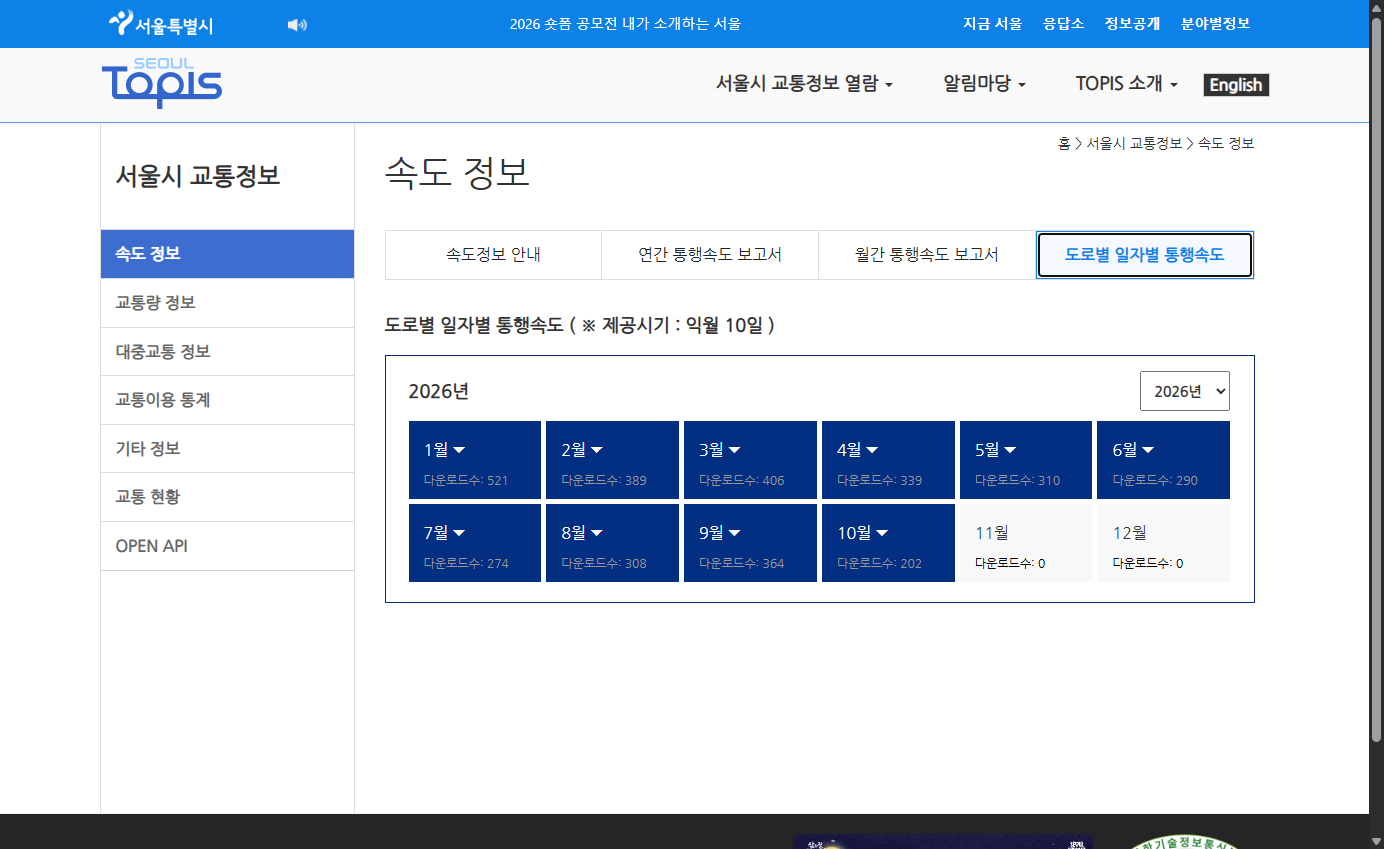

**topis_2022_after**

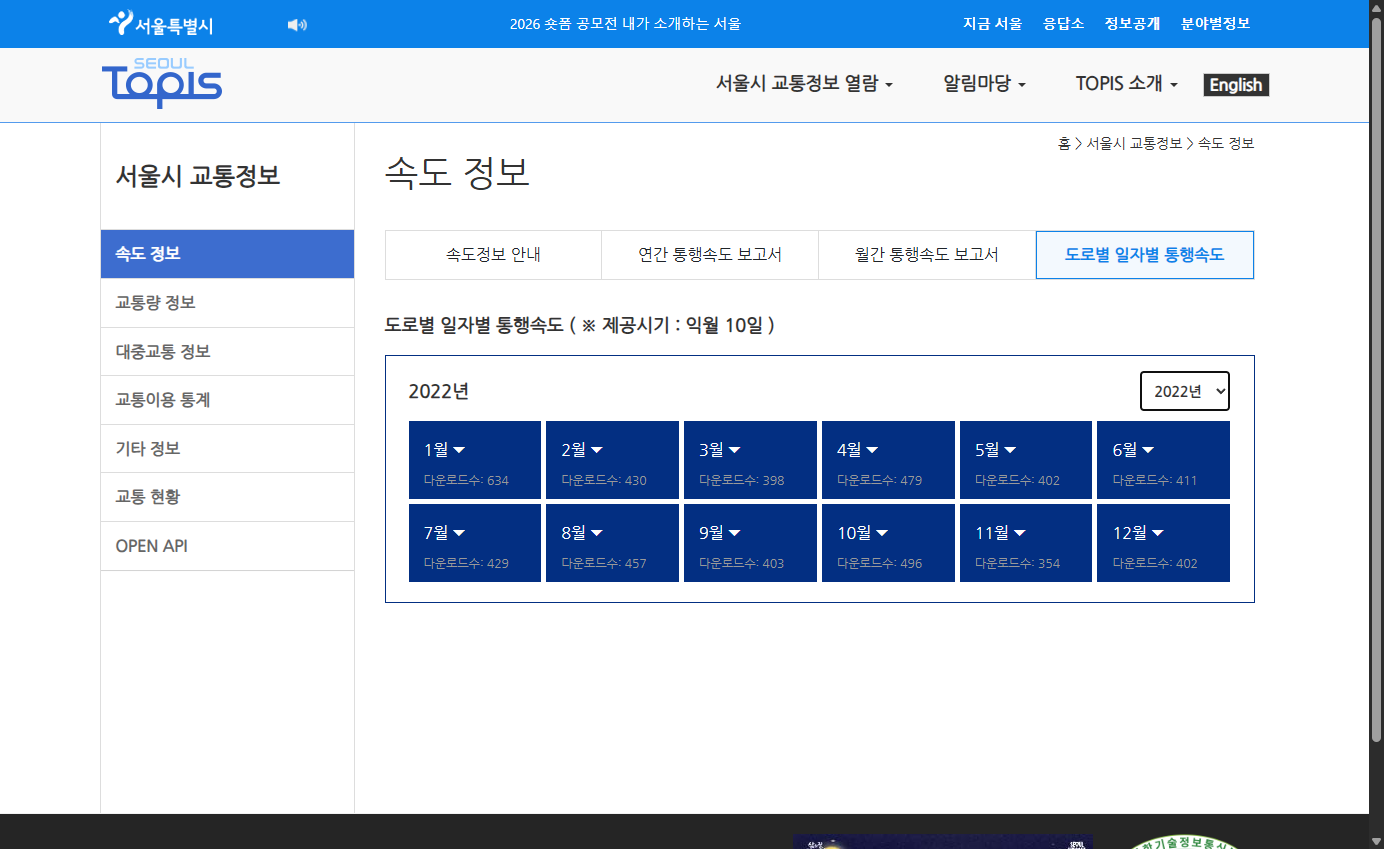

**topis_2023_after**

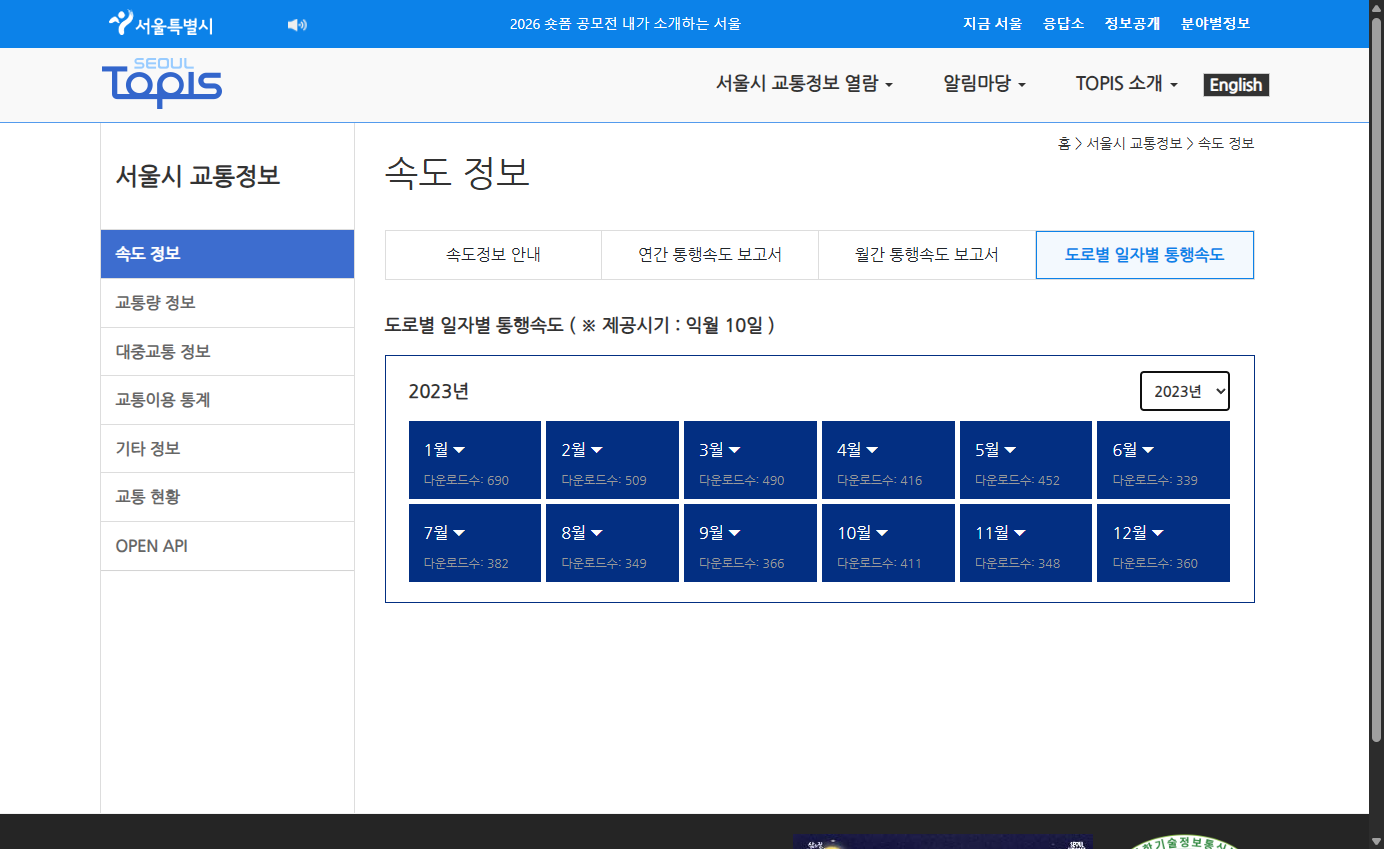

**topis_2024_after**

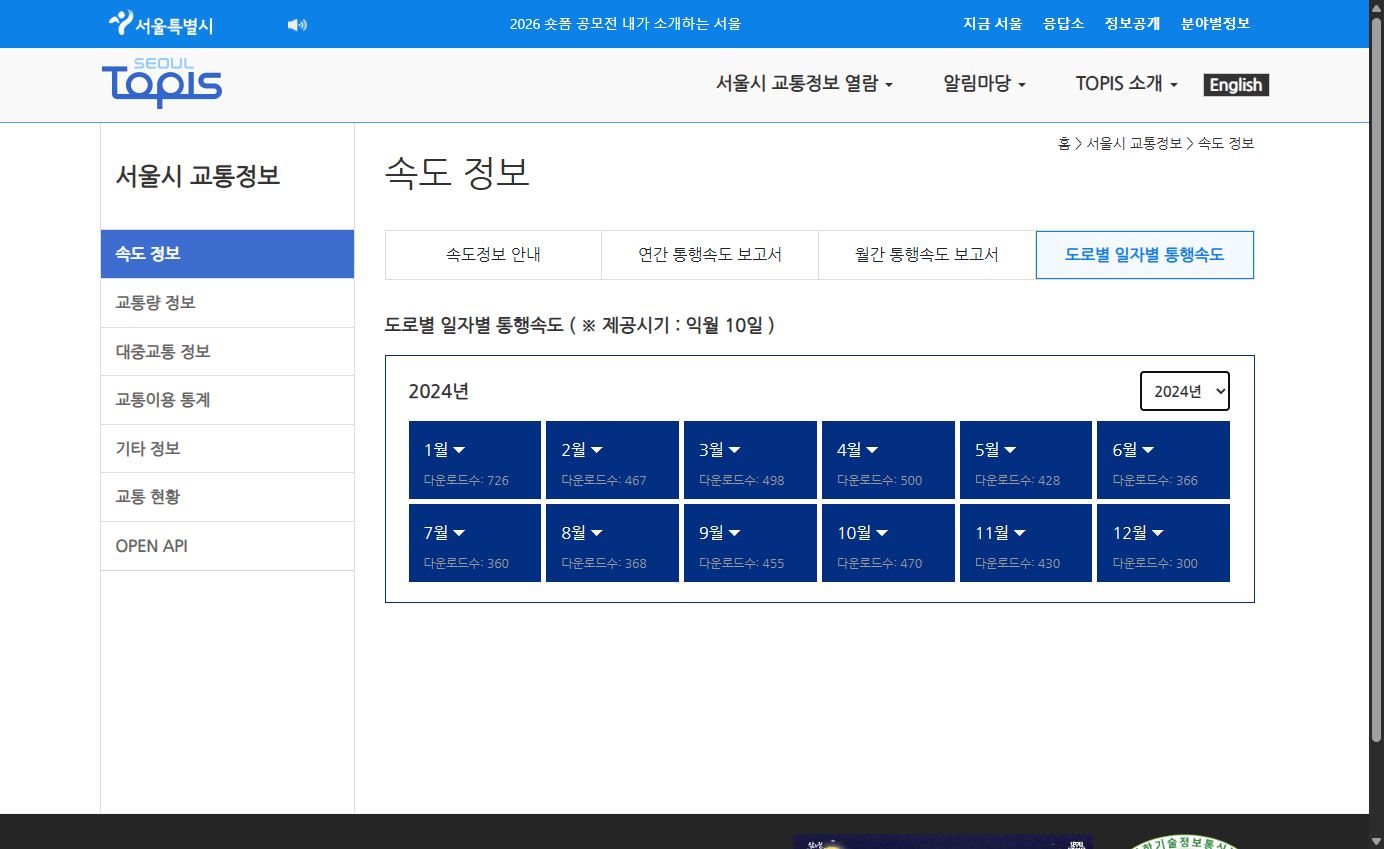

**topis_2025_after**

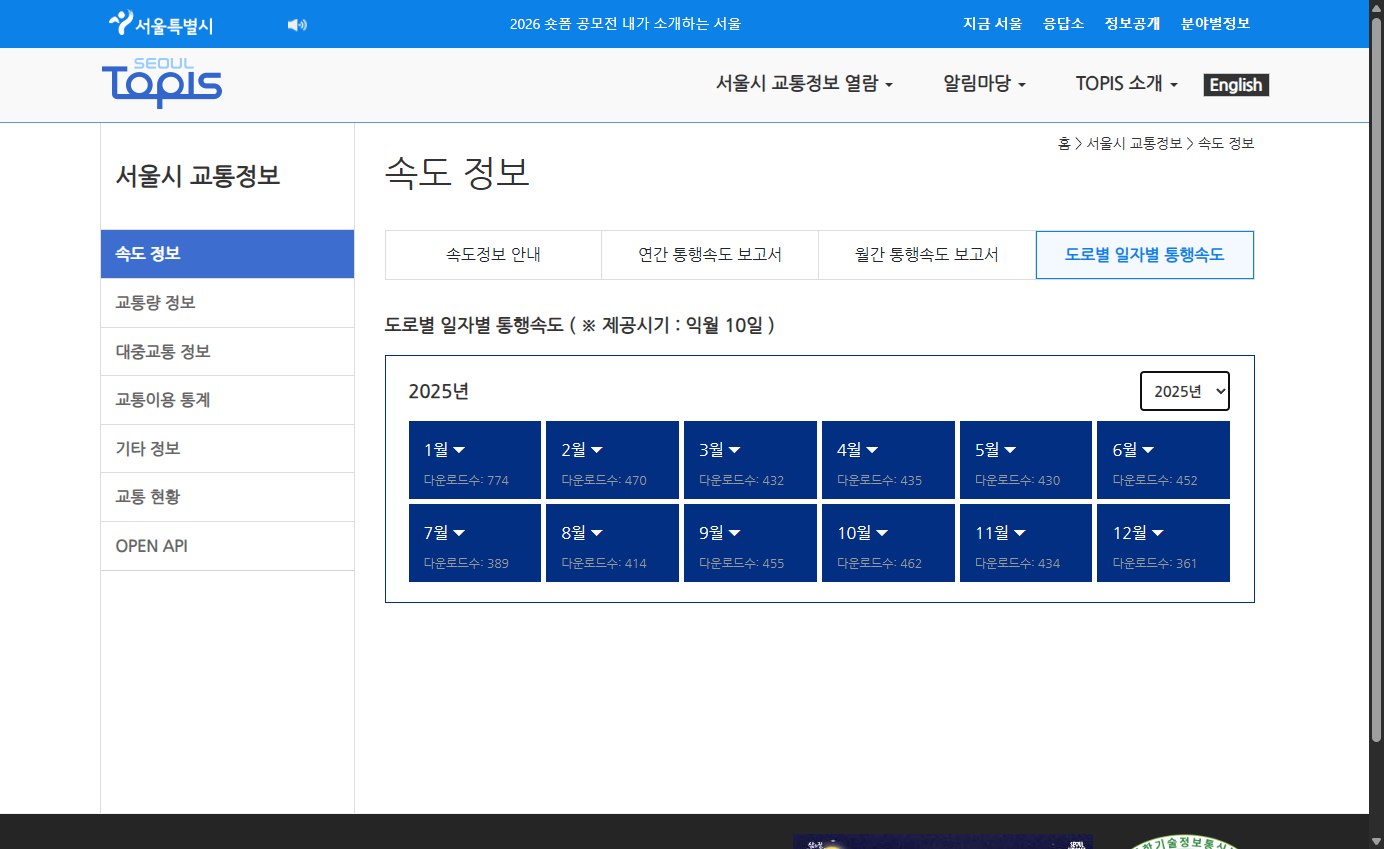

**topis_2026_after**

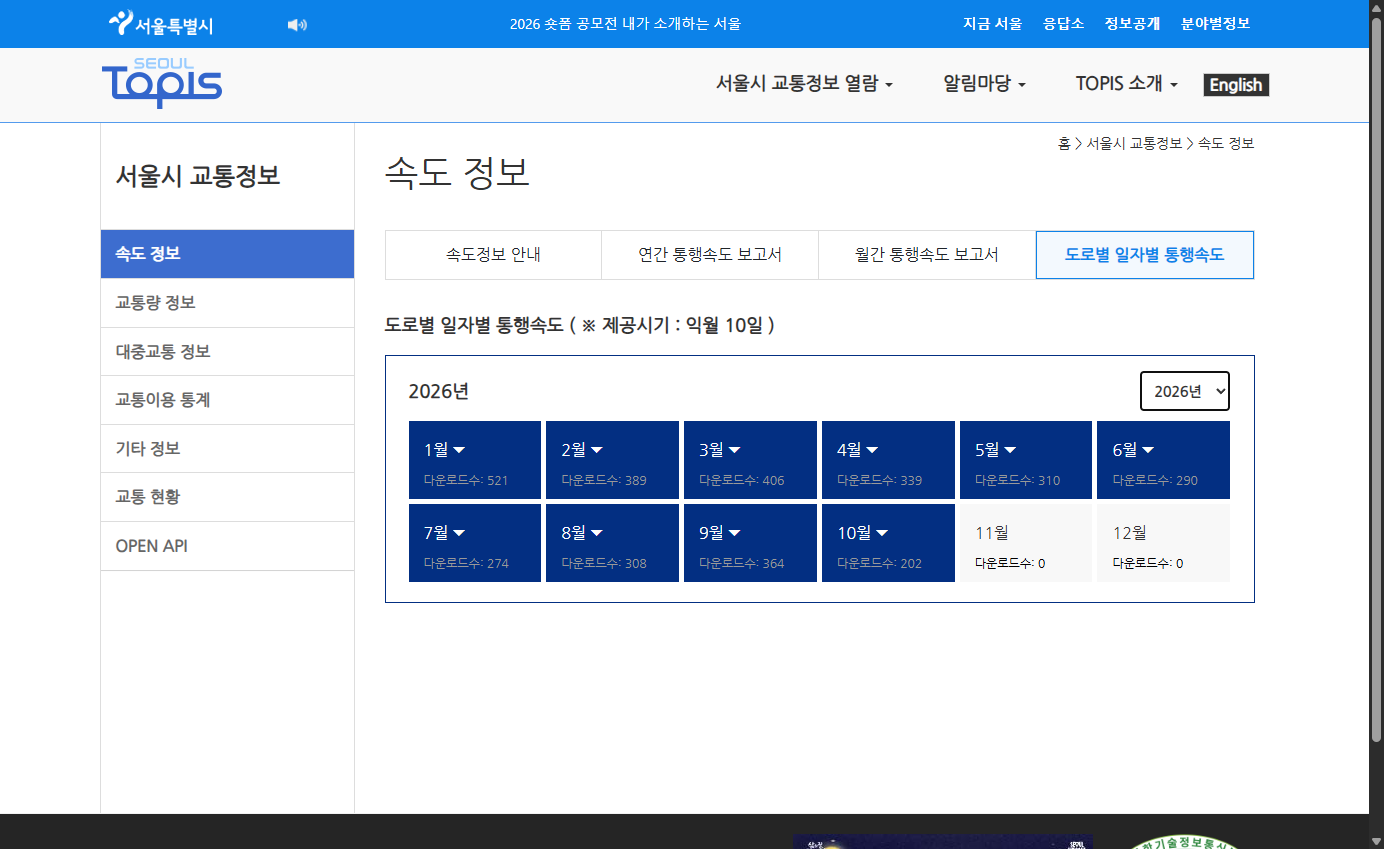

In [3]:
for p in sorted((ROOT / 'logs/kmj/topis_speed').glob('topis_*.png')):
    display(Markdown(f'**{p.stem}**'), Image(filename=str(p), width=750))

### 1-3. 네트워크 분석으로 찾은 요청

브라우저가 보내는 요청을 기록해 보니, 연도 목록, 게시글 목록, 파일 받기가 모두 POST 요청이었다. 화면 클릭 대신 이 요청을 같은 세션으로 보내서 받는다.

In [4]:
net = log_lines('logs/kmj/topis_speed/topis_network.log', n=6)
pd.Series([re.search(r'(POST|GET) \S+/(\w+\.do)', l).group(2) for l in net if '.do' in l]).value_counts().rename('횟수').to_frame()

logs/kmj/topis_speed/topis_network.log, 29줄, 2026-11-20 21:30 ~ 2026-11-25 01:30
  2026-11-25 01:30:53 | POST https://topis.seoul.go.kr/refroom/selectYearList.do | blbdDivCd=06
  2026-11-25 01:30:53 | POST https://topis.seoul.go.kr/refroom/selectRefRoomListASC.do | blbdDivCd=06&bdwrDivCd=2026&mainBdwrRowNum=12
  2026-11-25 01:30:53 | POST https://topis.seoul.go.kr/refroom/selectRefRoomListASC.do | blbdDivCd=06&bdwrDivCd=2022&mainBdwrRowNum=12
  2026-11-25 01:30:53 | POST https://topis.seoul.go.kr/refroom/selectRefRoomListASC.do | blbdDivCd=06&bdwrDivCd=2023&mainBdwrRowNum=12
  2026-11-25 01:30:53 | POST https://topis.seoul.go.kr/refroom/selectRefRoomListASC.do | blbdDivCd=06&bdwrDivCd=2024&mainBdwrRowNum=12
  2026-11-25 01:30:53 | POST https://topis.seoul.go.kr/refroom/selectRefRoomListASC.do | blbdDivCd=06&bdwrDivCd=2025&mainBdwrRowNum=12


,횟수
selectRefRoomListASC.do,23
selectYearList.do,6


### 1-4. 실행 로그, 결과 (manifest)

In [5]:
log = log_lines('logs/kmj/topis_speed/topis_speed.log', pattern=r'FAIL|WARN|=== 끝', n=12)
man = pd.read_csv(ROOT / 'logs/kmj/topis_speed/topis_manifest.csv', encoding='utf-8-sig')
print(f'\nmanifest {len(man)}개월, 상태', man['상태'].value_counts().to_dict(),
      f', 행 {man["행수"].sum():,}, 링크 {man["링크수"].min():,}~{man["링크수"].max():,}개')
man[['연월', '상태', '크기MB', '행수', '링크수', '날짜수', '결측률', '메모', '수집시각']]

logs/kmj/topis_speed/topis_speed.log, 210줄, 2026-11-20 21:01 ~ 2026-11-25 01:30
  2026-11-20 21:01:15 | FAIL | 2024-12 | NoSuchElementException: Message: Cannot locate option with value: 2024; For documentation on this error, please visit: https://www.
  2026-11-20 21:30:05 | === 끝: OK 4 · WARN 0 · FAIL 0 · 건너뜀 0 ===
  2026-11-20 21:30:40 | === 끝: SKIP 4 ===
  2026-11-20 21:32:45 | === 끝: OK 4 ===
  2026-11-20 21:34:02 | [WARN] 2024-11: 152,187행, 링크 5,075, 30/30일, 결측률 1.14% (결측률 1.14% 높음)
  2026-11-20 21:34:48 | === 끝: OK 3, WARN 1 ===
  2026-11-20 22:03:30 | [WARN] 2024-08: 157,204행, 링크 5,073, 31/31일, 결측률 1.44% (결측률 1.44% 높음)
  2026-11-20 22:05:24 | [WARN] 2025-07: 157,422행, 링크 5,079, 31/31일, 결측률 1.65% (결측률 1.65% 높음)
  2026-11-20 22:08:49 | [WARN] 2026-07: 157,278행, 링크 5,075, 31/31일, 결측률 1.52% (결측률 1.52% 높음)
  2026-11-20 22:09:27 | === 끝: OK 38, SKIP 4, WARN 3 ===
  2026-11-25 01:30:55 | === 끝: OK 4 ===

manifest 49개월, 상태 {'OK': 45, 'WARN': 4} , 행 7,564,847, 링크 5,056~5,083개


,연월,상태,크기MB,행수,링크수,날짜수,결측률,메모,수집시각
0,2022-08,OK,36.7,156677,5059,31,0.0008,NaN,2026-11-20T21:57:22
1,2022-10,OK,36.7,156811,5059,31,0.0005,NaN,2026-11-25T01:29:55
2,2022-11,OK,35.6,151758,5062,30,0.0009,NaN,2026-11-20T21:57:39
3,2022-12,OK,36.7,156736,5056,31,0.0007,NaN,2026-11-20T21:57:57
4,2023-01,OK,34.4,156814,5062,31,0.0004,NaN,2026-11-20T21:58:15
5,2023-02,OK,31.1,141736,5062,28,0.0003,NaN,2026-11-20T21:58:31
6,2023-03,OK,34.5,156938,5063,31,0.0003,NaN,2026-11-20T21:58:49
7,2023-04,OK,33.3,151854,5063,30,0.0005,NaN,2026-11-20T21:59:07
8,2023-05,OK,34.5,156891,5061,31,0.0004,NaN,2026-11-20T21:59:24
9,2023-06,OK,33.3,151823,5061,30,0.0003,NaN,2026-11-20T21:59:42


- WARN 4개월은 결측률이 1%를 넘은 달이다. 날짜별로 보면 모두 금요일 밤~토요일 아침에 서울 전체가 동시에 비어 있었다 (수집 시스템 공백).
  연구 기간 안의 41시간은 `config/topis_gaps.csv`에 두고, 행은 지우지 않고 빈값으로 둔다 (자세한 확인: `01_shared/kmj_topis_check`).
- 원본 엑셀은 빈칸 대신 `NULL` 글자를 쓴다. 처음엔 결측이 0으로 나와서 `NULL`을 빈값으로 세도록 고쳤다.

---
## 2. TOPIS 교통예보 스냅샷, Selenium + JSON 요청 (매일 자동)

- 목적: 기존 TOPIS 교통예보가 비, 눈을 반영하는지 보려고, 비 오는 날의 예보를 실제 속도와 비교한다 (노션 결과 3.8)
- 흐름: 예보 페이지를 열고 주간 예보 표가 그려질 때까지 대기 -> 캡처 -> 같은 세션으로 페이지가 쓰는 JSON 요청 4종을 직접 호출
- 대상: 분석 도로 90개 중 예보에 있는 87개 x 2방향 x 오늘, 내일 07~20시 (서부간선지하도로, 신월여의지하도로, 녹사평대로는 예보에 없음)
- 실행: GitHub Actions `.github/workflows/topis_forecast.yml`, 매일 05:17 KST (07:41에 빠진 날만 한 번 더). 결과는 `data-collect` 브랜치

In [6]:
show_func('crawling/topis_forecast.py', 'post', 'axis_map')

**`crawling/topis_forecast.py`, `post()`** (88–98행)
```python
def post(session, path, data, retries=3):
    for attempt in range(1, retries + 1):
        try:
            r = session.post(BASE + path, data=data, timeout=30)
            r.raise_for_status()
            return r.json().get("rows", [])
        except (requests.RequestException, ValueError) as e:
            if attempt == retries:
                raise
            log(f"  [재시도 {attempt}/{retries}] {path} {data}: {e}")
            time.sleep(3 * attempt)
```

**`crawling/topis_forecast.py`, `axis_map()`** (101–108행)
```python
def axis_map(session, road_names):
    rows = []
    for name in road_names:
        hits = [r for r in post(session, "/prdc/selectRoadNameList.do", {"sRoadName": name}) if r["axisName"] == name]
        rows.append({"road_name": name, "axisCd": hits[0]["axisCd"] if hits else None,
                     "stNodeNm": hits[0]["stNodeNm"] if hits else None, "edNodeNm": hits[0]["edNodeNm"] if hits else None})
        time.sleep(PAUSE_SEC)
    return pd.DataFrame(rows)
```

logs/kmj/topis_forecast/topis_forecast.log, 7줄, 2026-11-25 23:04 ~ 2026-11-25 23:08
  2026-11-25 23:04:53 | === 교통예보 수집 시작: 2026-11-25, 2026-11-26 ===
  2026-11-25 23:05:58 | === 교통예보 수집 시작: 2026-11-25, 2026-11-26 ===
  2026-11-25 23:06:26 | [주간] 35행
  2026-11-25 23:06:26 | [도로 종류별] 140행
  2026-11-25 23:06:49 | [도로 코드] 87/90개 도로가 예보에 있음
  2026-11-25 23:08:26 | [구간] 47950행, 링크 1714개, 실패 0건
  2026-11-25 23:08:28 | === 끝: data\raw\forecast\2026-11-25 ===


**forecast_2026-11-25** (주간 예보 표가 그려진 뒤 캡처)

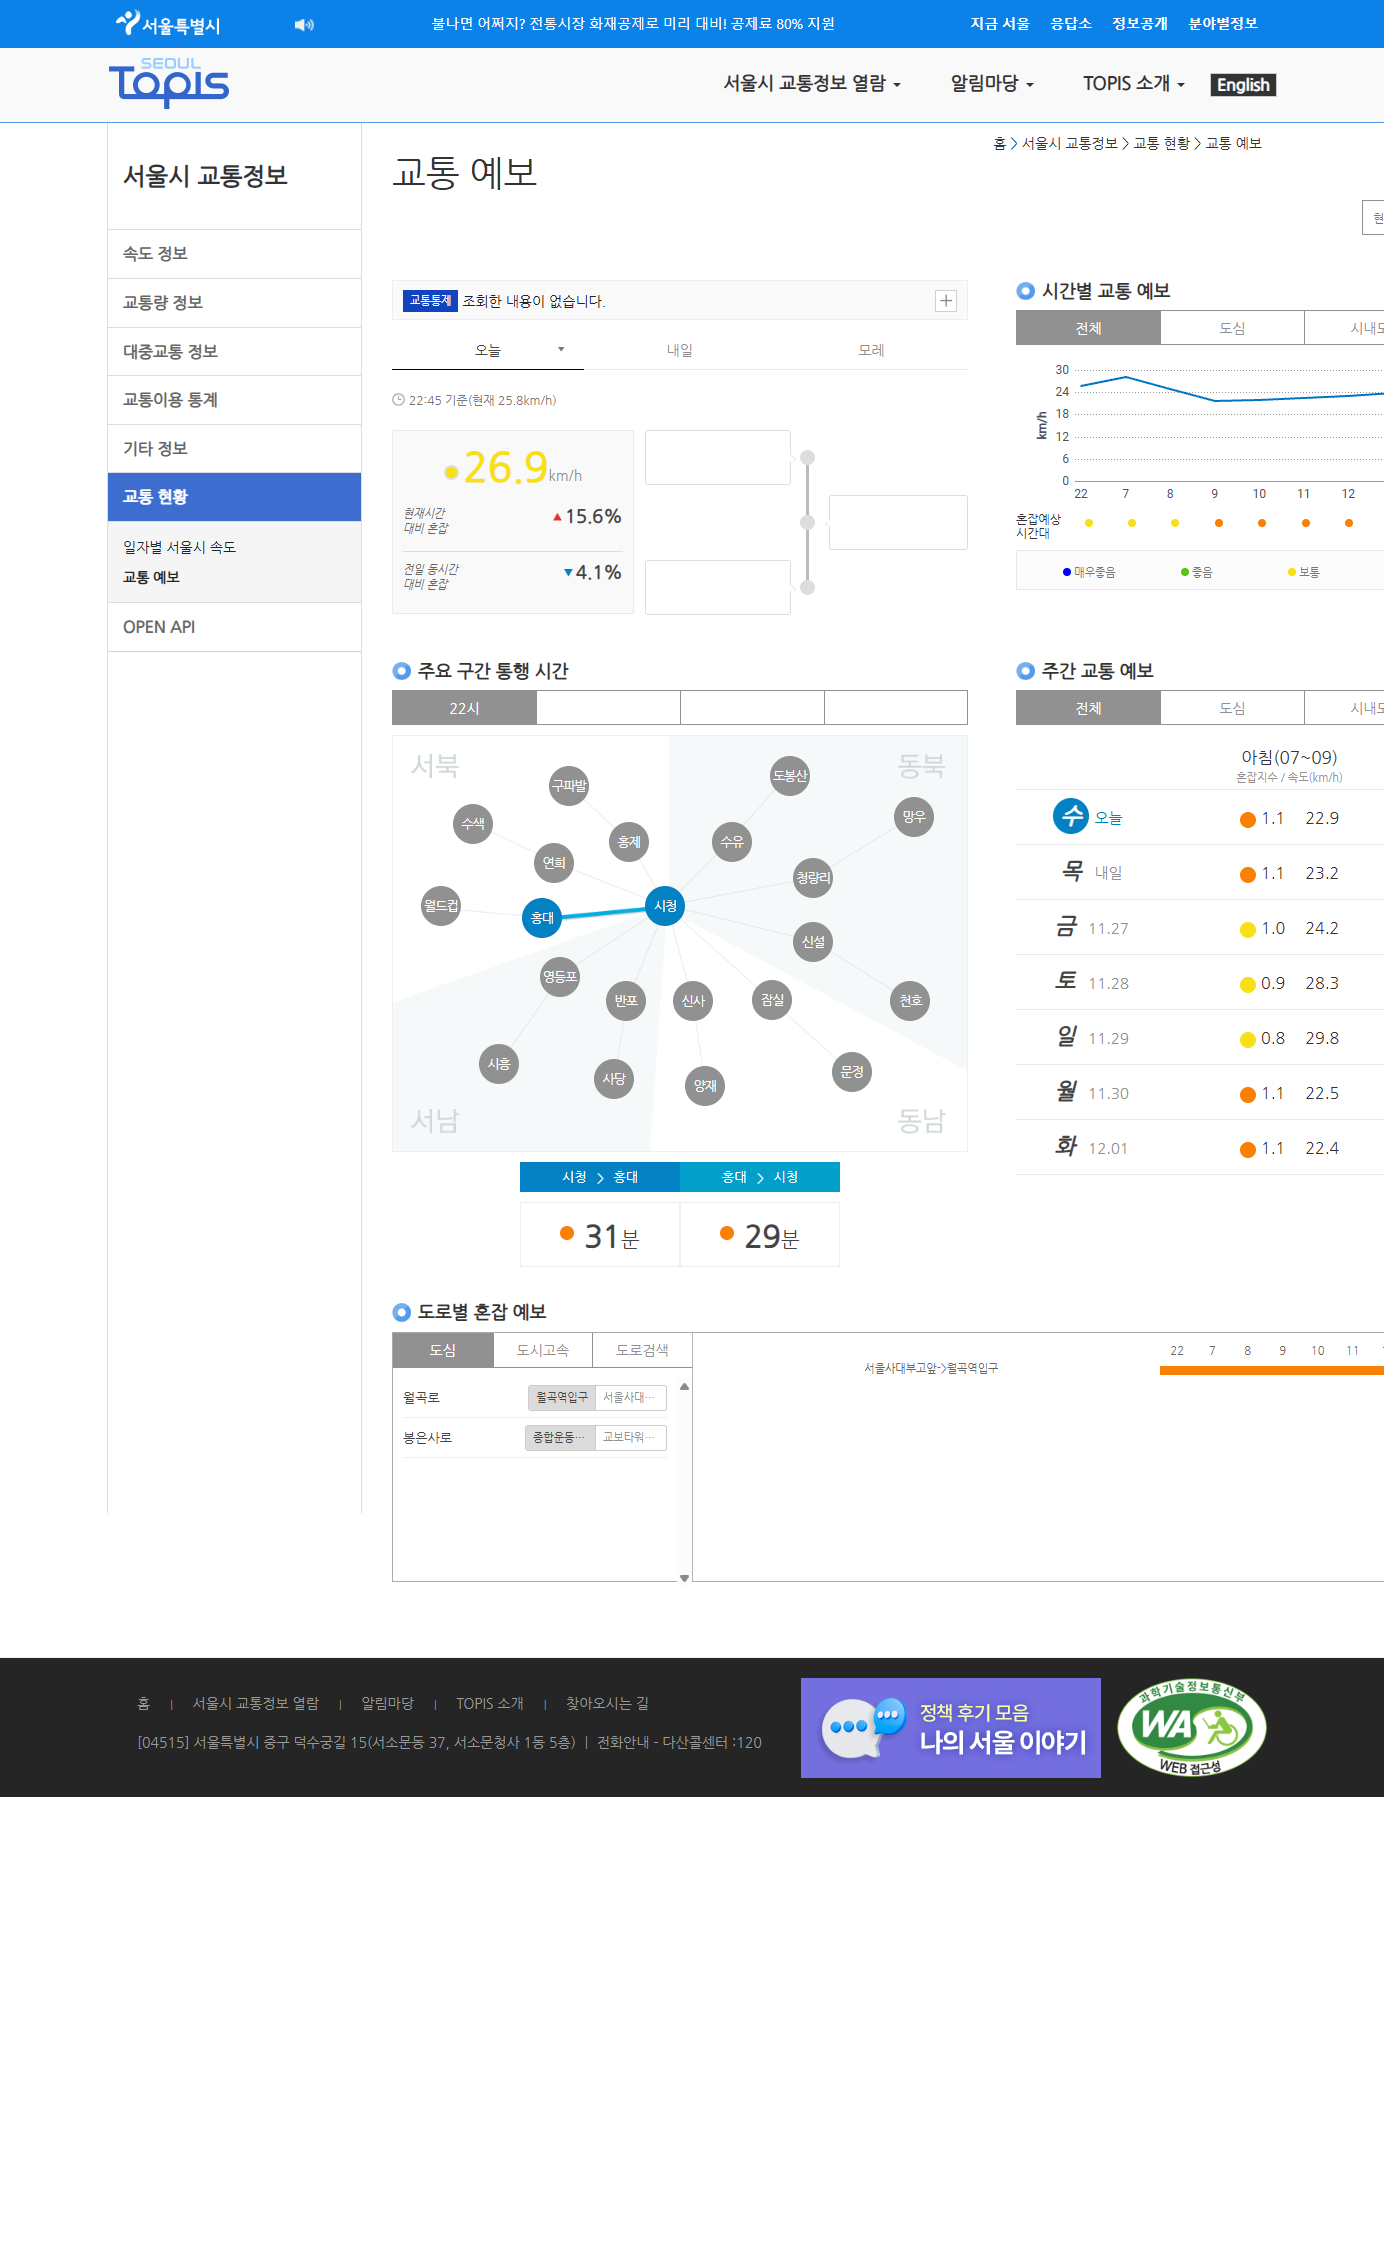

In [7]:
log_lines('logs/kmj/topis_forecast/topis_forecast.log', n=7)
for p in sorted((ROOT / 'logs/kmj/topis_forecast').glob('forecast_*.png')):
    display(Markdown(f'**{p.stem}** (주간 예보 표가 그려진 뒤 캡처)'), Image(filename=str(p), width=750))

In [8]:
files = collected('data/raw/topis_forecast')
fc = pd.DataFrame({'path': files})
fc['날짜'] = fc['path'].str.extract(r'topis_forecast/(\d{4}-\d{2}-\d{2})/')[0]
fc['파일'] = fc['path'].str.split('/').str[-1]
print(f'data-collect에 쌓인 예보: {fc["날짜"].nunique()}일')
fc.groupby('날짜')['파일'].apply(', '.join).to_frame()

data-collect에 쌓인 예보: 3일


,파일
날짜,
2026-11-25,"axis_map.csv, link_hourly.csv, roadtype_hourly..."
2026-11-26,"axis_map.csv, link_hourly.csv, roadtype_hourly..."
2026-11-27,"axis_map.csv, link_hourly.csv, roadtype_hourly..."


---
## 3. 실시간 도로 소통 정보, 서울 열린데이터광장 API (평일 출퇴근 자동)

- 목적: TOPIS 12월 통행속도 파일은 1/10에 올라와 발표 전에 못 받는다. 그래서 12/11까지 평일 출퇴근 실제 속도를 직접 저장해 교통예보와 비교한다
- API: TrafficInfo, 링크 1개당 1번 호출, XML. 응답 link_id, prcs_spd, prcs_trv_time. 데이터셋 페이지(OA-13291)는 '종료'로 나오지만 API는 응답한다
- 대상: 안정 링크 1,753개 (180개 도로, 방향), 동시 8개로 약 1분
- 실행: GitHub Actions `.github/workflows/realtime_speed.yml`, 평일 07:20, 07:45, 08:20, 08:45, 17:20 ~ 19:45 (30분마다)
- 인증키는 GitHub Secret(SEOUL_OPEN_DATA_API_KEY)에서만 읽고, 주소, 로그에 남기지 않는다

In [9]:
show_func('crawling/realtime_speed.py', 'fetch', 'collect', 'road_summary')

**`crawling/realtime_speed.py`, `fetch()`** (67–76행)
```python
def fetch(session, key: str, link: dict) -> dict:
    now = datetime.now(KST)
    row = dict(link, called_at=now.isoformat(timespec="seconds"), hour_end=hour_end(now))
    try:
        r = session.get(URL.format(key=key, link_id=link["link_id"]), timeout=20)
        r.raise_for_status()
        row.update(parse(r.content))
    except Exception as e:  # 오류 문구에 주소(키 포함)가 들어갈 수 있어 종류만 남긴다
        row.update(code=f"EXC:{type(e).__name__}", prcs_spd="", prcs_trv_time="")
    return row
```

**`crawling/realtime_speed.py`, `collect()`** (79–90행)
```python
def collect(session, key: str, links: list[dict]) -> list[dict]:
    with ThreadPoolExecutor(max_workers=WORKERS) as ex:
        rows = list(ex.map(lambda l: fetch(session, key, l), links))
    retry = [i for i, r in enumerate(rows) if r["code"] != OK or not r["prcs_trv_time"]]
    if retry:
        time.sleep(3)
        with ThreadPoolExecutor(max_workers=WORKERS) as ex:
            again = list(ex.map(lambda i: fetch(session, key, links[i]), retry))
        for i, r in zip(retry, again):
            if r["code"] == OK and r["prcs_trv_time"]:
                rows[i] = r
    return rows
```

**`crawling/realtime_speed.py`, `road_summary()`** (93–110행)
```python
def road_summary(rows: list[dict]) -> list[dict]:
    groups: dict[tuple, list[dict]] = {}
    for r in rows:
        groups.setdefault((r["road_id"], r["road_name"], r["direction"]), []).append(r)
    out = []
    for (road_id, road_name, direction), g in sorted(groups.items()):
        ok = [r for r in g if r["code"] == OK and r["prcs_trv_time"] != ""]
        complete = len(ok) == len(g)
        out.append({
            "road_id": road_id,
            "road_name": road_name,
            "direction": direction,
            "n_links": len(g),
            "n_ok": len(ok),
            "trv_time_s": sum(float(r["prcs_trv_time"]) for r in ok) if complete else "",
            "hour_end": g[0]["hour_end"],
        })
    return out
```

In [10]:
summ = [f for f in collected('data/raw/realtime_speed') if f.endswith('_summary.json')]
rt = pd.DataFrame([json.loads(collected_text(f)) for f in summ])
if len(rt):
    rt['codes'] = rt['codes'].astype(str)
print(f'data-collect에 쌓인 실시간 저장 {len(rt)}회')
rt

data-collect에 쌓인 실시간 저장 1회


,started_at,hour_end,links,links_ok,roads_complete,roads,codes,seconds
0,2026-11-27T20:46:35+09:00,21,1753,1753,180,180,{'INFO-000': 1753},41.7


11/27 20:46에 손으로 한 번 실행했을 때 링크 1,753개 모두 정상 응답(INFO-000)이었고, 도로, 방향 180개가 모두 채워졌다 (42초).
하루 10번(약 17,500번) 호출이 한도에 걸리는지는 쌓이는 `_summary.json`의 응답 코드로 확인한다.

---
## 4. 문제 -> 원인 -> 해결

| 자료 | 문제 (로그, 증상) | 원인 | 해결 | 결과 |
| --- | --- | --- | --- | --- |
| 통행속도 | 연도 선택에서 `NoSuchElementException: Cannot locate option with value: 2024` | 연도 목록이 페이지가 열린 뒤 별도 요청(`selectYearList.do`)으로 늦게 채워짐 | 옵션이 생길 때까지 기다리고, 목록이 새 연도로 바뀐 것을 확인한 뒤 읽기 | 50개월 모두 받음 |
| 통행속도 | 클릭으로 받으면 파일 이름, 저장 위치가 제각각 | 다운로드가 화면 버튼이 아니라 POST 요청 | 네트워크 기록에서 `downloadFileRefRoom.do`와 인자를 찾아 Selenium 쿠키로 `requests` 세션에서 직접 받기 | 재시도, 이어받기, 검증 가능 |
| 통행속도 | 결측률이 0으로 나옴 | TOPIS는 빈칸 대신 `NULL` 글자를 씀 | `NULL`을 빈값으로 세도록 검증 수정 | 결측 1% 넘는 4개월 발견 |
| 통행속도 | 2024-02 이전 파일만 열 이름이 `08시` | 파일 형식이 2024-03부터 `~08시`로 바뀜 | `read_topis()`에서 이름을 맞춤 | 50개월 같은 열 |
| 통행속도 | `~08시`가 몇 시 평균인지 안 나옴 | 자료 설명에 없음 | TOPIS 월간 보고서와 대조 (총거리/총시간, 오차 0.07~0.09km/h) | 07:00~08:00 평균으로 확정 |
| 통행속도 | 결측이 1% 넘는 달 | 금 밤~토 아침 서울 전체 동시 결측 (시스템 공백) | 연구 기간 41시간을 `config/topis_gaps.csv`에 두고 빈값 처리 | 팀 결정(11/20) |
| 교통예보 | 표를 읽기 전에 페이지가 끝난 것으로 판단 | 표 칸(`td`)이 아니라 목록(`li.cont`)으로 그려짐 | 기다리는 대상을 `li.cont`로 변경 | 캡처, 요청 정상 |
| 교통예보 | Actions에서만 `--out` 경로 오류 | 상대 경로를 저장소 기준으로 바꾸는 부분 | PR #22에서 수정 | 매일 저장 |
| 자동 수집 | 예약(schedule) 실행이 한 번도 안 돎 (11/27 06:00 예보, 17:20 ~ 19:45 실시간 6번) | 원인 미확인. 예약이 등록되지 않은 것으로 추정 | 워크플로를 껐다 켜서 다시 등록 + 손으로 한 번 실행. 계속 안 되면 외부 예약 서비스로 수동 실행 주소 호출 | 손 실행 정상, 예약은 11/28 05:17부터 확인 |
| 실시간 | 데이터셋 페이지가 '종료'로 나옴 | 안내만 바뀌고 API는 살아 있음 | 시험 호출 250번(1개씩 50, 동시 8개 200) 모두 INFO-000 확인 후 진행 | 1,753개 정상 |
| 공통 | 인증키가 주소에 들어감 | API 주소 형식이 `/{KEY}/xml/...` | 키는 Secret, 환경변수에서만, 오류 문구에서 키를 `***`로 가림 | 로그에 키 없음 |

---
## 정리

| 자료 | 결과 | 위치 |
| --- | --- | --- |
| TOPIS 통행속도 | 50개월 월별 CSV (manifest 49개월에 행, 링크, 결측률) | 팀 공유 드라이브 -> `data/raw/topis_speed/` |
| TOPIS 교통예보 | 매일 오늘, 내일 07~20시, 87개 도로 x 2방향 구간 예보 | `data-collect` 브랜치 `data/raw/topis_forecast/` |
| 실시간 속도 | 평일 출퇴근 하루 10번, 링크 1,753개 | `data-collect` 브랜치 `data/raw/realtime_speed/` |